# PHÂN TÍCH KHÁM PHÁ DỮ LIỆU ĐÁNH GIÁ TMĐT (EDA)

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
PROC_DIR = os.path.join(ROOT, 'data', 'processed')
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

In [3]:
#Chỉ nạp tập train sạch để phân tích EDA, tuyệt đối không nhìn dev/test
df_train = pd.read_csv(os.path.join(PROC_DIR, 'train_clean.csv'))

In [4]:
df_train.shape

(7776, 16)

In [5]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 7776 entries, 0 to 7775
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   index           7776 non-null   int64
 1   sentence        7776 non-null   str  
 2   n_star          7776 non-null   int64
 3   date_time       7776 non-null   str  
 4   label           7776 non-null   str  
 5   sentiment       7776 non-null   int64
 6   aspect_group    7776 non-null   int64
 7   asp_0           7776 non-null   int64
 8   asp_1           7776 non-null   int64
 9   asp_2           7776 non-null   int64
 10  asp_3           7776 non-null   int64
 11  asp_4           7776 non-null   int64
 12  all_aspects     7776 non-null   str  
 13  sentence_clean  7776 non-null   str  
 14  is_no_content   7776 non-null   bool 
 15  sentence_seg    7776 non-null   str  
dtypes: bool(1), int64(9), str(6)
memory usage: 6.1 MB


In [6]:
df_train.head()

,index,sentence,n_star,date_time,label,sentiment,aspect_group,asp_0,asp_1,asp_2,asp_3,asp_4,all_aspects,sentence_clean,is_no_content,sentence_seg
0,0,Mới mua máy này Tại thegioididong thốt nốt cảm...,5,2 tuần trước,{CAMERA#Positive};{FEATURES#Positive};{BATTERY...,2,2,1,1,1,1,1,"0,1,2,3,4",Mới mua máy này Tại thegioididong thốt nốt cảm...,False,Mới mua máy này Tại thegioididong thốt_nốt cảm...
1,1,Pin kém còn lại miễn chê mua 8/3/2019 tình trạ...,5,14/09/2019,{BATTERY#Negative};{GENERAL#Positive};{OTHERS};,1,2,0,0,1,0,1,"2,4",Pin kém còn lại miễn chê mua 8/3/2019 tình trạ...,False,Pin kém còn lại miễn chê mua 8 / 3 / 2019 tình...
2,2,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nh...,3,17/08/2020,{FEATURES#Negative};,0,0,1,0,0,0,0,0,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nh...,False,Sao lúc gọi điện_thoại màn_hình bị chấm nhỏ nh...
3,3,"Mọi người cập nhật phần mềm lại , nó sẽ bớt tố...",3,29/02/2020,{FEATURES#Negative};{BATTERY#Neutral};{GENERAL...,1,0,1,0,1,0,1,"0,2,4","Mọi người cập nhật phần mềm lại , nó sẽ bớt tố...",False,"Mọi người cập_nhật phần_mềm lại , nó sẽ bớt tố..."
4,4,"Mới mua Sài được 1 tháng thấy pin rất trâu, Sà...",5,4/6/2020,{BATTERY#Positive};{PERFORMANCE#Positive};{SER...,2,3,1,0,1,1,0,"0,2,3","Mới mua Sài được 1 tháng thấy pin rất trâu, Sà...",False,"Mới mua Sài được 1 tháng thấy pin rất trâu , S..."


## 1. PHÂN BỐ CẢM XÚC, KHÍA CẠNH VÀ ĐA NHÃN

In [7]:
#Thống kê tần suất 3 lớp cảm xúc thuần túy
df_train['sentiment'].value_counts().sort_index()

sentiment
0    2517
1    1524
2    3735
Name: count, dtype: int64

In [8]:
#Thống kê tần suất khía cạnh chính (primary aspect_group)
df_train['aspect_group'].value_counts().sort_index()

aspect_group
0    3191
1     936
2    1640
3    1096
4     913
Name: count, dtype: int64

In [9]:
#Thống kê tần suất đa nhãn asp_0..asp_4 và số khía cạnh trung bình mỗi câu
asp_cols = ['asp_0', 'asp_1', 'asp_2', 'asp_3', 'asp_4']
df_train[asp_cols].sum()

asp_0    5494
asp_1    2692
asp_2    3598
asp_3    3512
asp_4    6151
dtype: int64

In [10]:
df_train[asp_cols].sum(axis=1).value_counts().sort_index()

1    1008
2    2414
3    2323
4    1513
5     518
Name: count, dtype: int64

In [11]:
#Thống kê phân bố số sao đánh giá của khách hàng
df_train['n_star'].value_counts().sort_index()

n_star
1    1270
2     566
3    1011
4    1265
5    3664
Name: count, dtype: int64

## 2. BIỂU ĐỒ PHÂN BỐ CẢM XÚC VÀ KHÍA CẠNH

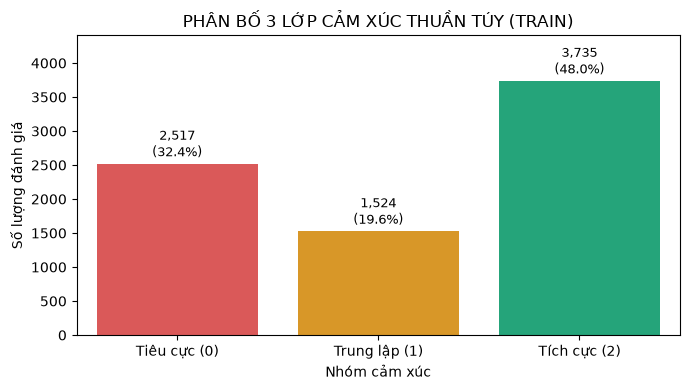

In [12]:
#Vẽ biểu đồ phân bố 3 lớp cảm xúc kèm nhãn trục rõ ràng
plt.figure(figsize=(7, 4))
sent_names = ['Tiêu cực (0)', 'Trung lập (1)', 'Tích cực (2)']
counts = df_train['sentiment'].value_counts().sort_index()
ax = sns.barplot(x=sent_names, y=counts.values, hue=sent_names, legend=False, palette=['#EF4444', '#F59E0B', '#10B981'])
for bar, val in zip(ax.patches, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 50, f'{val:,}\n({val/len(df_train):.1%})', ha='center', va='bottom', fontsize=9)
plt.ylim(0, counts.max() * 1.18)
plt.title('PHÂN BỐ 3 LỚP CẢM XÚC THUẦN TÚY (TRAIN)')
plt.xlabel('Nhóm cảm xúc')
plt.ylabel('Số lượng đánh giá')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_sentiment_dist.png'), dpi=300)
plt.show()

In [13]:
#Sắp xếp nhóm khía cạnh giảm dần theo tần suất và tô màu phân biệt từng nhóm
asp_label_map = {
    0: 'Hiệu năng & Cấu hình',
    1: 'Màn hình & Camera',
    2: 'Thời lượng Pin & Sạc',
    3: 'Giá cả & Hậu mãi',
    4: 'Thiết kế & Tổng quan',
}
asp_palette = {
    'Hiệu năng & Cấu hình': '#2563EB',
    'Thời lượng Pin & Sạc': '#10B981',
    'Giá cả & Hậu mãi': '#F59E0B',
    'Màn hình & Camera': '#8B5CF6',
    'Thiết kế & Tổng quan': '#64748B',
}
counts_asp = df_train['aspect_group'].value_counts()
asp_names_sorted = [asp_label_map[i] for i in counts_asp.index]

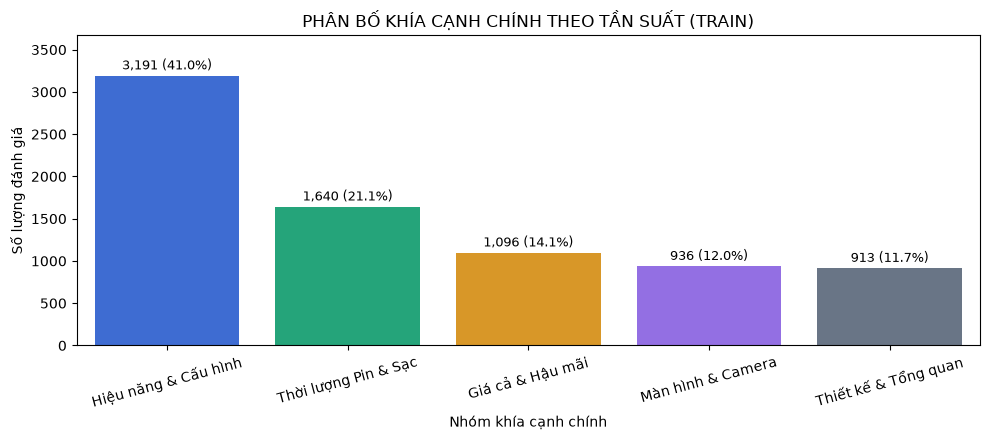

In [14]:
#Vẽ biểu đồ phân bố khía cạnh chính đã sắp xếp theo tần suất
plt.figure(figsize=(10, 4.5))
ax = sns.barplot(x=asp_names_sorted, y=counts_asp.values, hue=asp_names_sorted, legend=False, palette=asp_palette)
for bar, val in zip(ax.patches, counts_asp.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 40, f'{val:,} ({val/len(df_train):.1%})', ha='center', va='bottom', fontsize=9)
plt.ylim(0, counts_asp.max() * 1.15)
plt.title('PHÂN BỐ KHÍA CẠNH CHÍNH THEO TẦN SUẤT (TRAIN)')
plt.xlabel('Nhóm khía cạnh chính')
plt.ylabel('Số lượng đánh giá')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_aspect_dist.png'), dpi=300, bbox_inches='tight')
plt.show()

## 3. TƯƠNG QUAN SỐ SAO VÀ CẢM XÚC (MÂU THUẪN SAO THẬT)

In [15]:
#Bảng chéo giữa số sao n_star và nhãn cảm xúc thuần túy
pd.crosstab(df_train['n_star'], df_train['sentiment'], margins=True)

sentiment,0,1,2,All
n_star,,,,
1,1111,134,25,1270
2,426,117,23,566
3,603,308,100,1011
4,258,444,563,1265
5,119,521,3024,3664
All,2517,1524,3735,7776


In [16]:
#Tính tỷ lệ mâu thuẫn sao thật (1-2 sao khen hoặc 4-5 sao chê)
low_pos = int(((df_train['n_star'] <= 2) & (df_train['sentiment'] == 2)).sum())
high_neg = int(((df_train['n_star'] >= 4) & (df_train['sentiment'] == 0)).sum())
n_contra = low_pos + high_neg
print('Mâu thuẫn sao thật -> 1-2* Tích cực:', low_pos, '| 4-5* Tiêu cực:', high_neg, f'| Tổng: {n_contra}/{len(df_train)} ({n_contra/len(df_train):.2%})')

Mâu thuẫn sao thật -> 1-2* Tích cực: 48 | 4-5* Tiêu cực: 377 | Tổng: 425/7776 (5.47%)


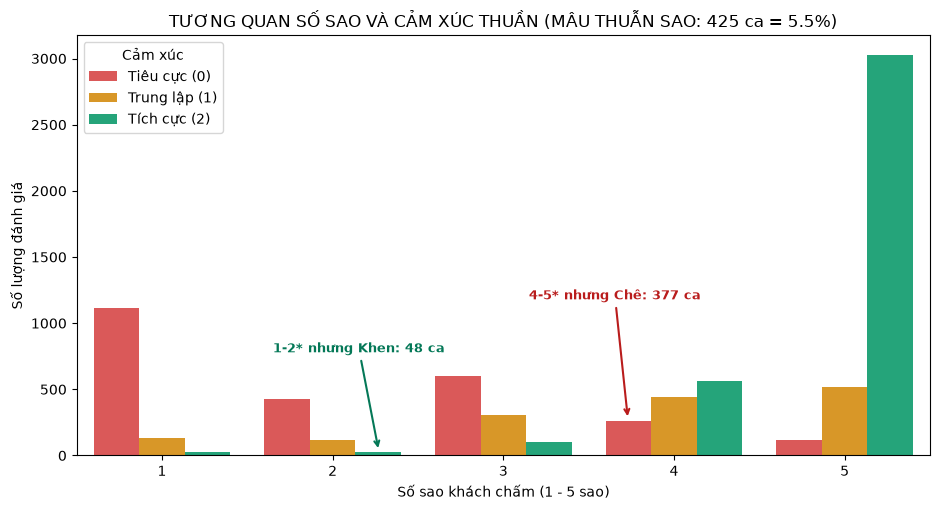

In [17]:
#Vẽ biểu đồ n_star vs sentiment nhấn mạnh các ca mâu thuẫn sao thật
plt.figure(figsize=(9.5, 5.2))
ax = sns.countplot(data=df_train, x='n_star', hue='sentiment', palette=['#EF4444', '#F59E0B', '#10B981'])
plt.title(f'TƯƠNG QUAN SỐ SAO VÀ CẢM XÚC THUẦN (MÂU THUẪN SAO: {n_contra} ca = {n_contra/len(df_train):.1%})')
plt.xlabel('Số sao khách chấm (1 - 5 sao)')
plt.ylabel('Số lượng đánh giá')
plt.legend(['Tiêu cực (0)', 'Trung lập (1)', 'Tích cực (2)'], title='Cảm xúc')
plt.annotate(f'1-2* nhưng Khen: {low_pos} ca', xy=(1.27, 35), xytext=(0.65, 780), arrowprops=dict(arrowstyle='->', color='#047857', lw=1.5), fontsize=9, fontweight='bold', color='#047857')
plt.annotate(f'4-5* nhưng Chê: {high_neg} ca', xy=(2.73, 275), xytext=(2.15, 1180), arrowprops=dict(arrowstyle='->', color='#B91C1C', lw=1.5), fontsize=9, fontweight='bold', color='#B91C1C')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_star_vs_sentiment.png'), dpi=300)
plt.show()

## 4. HEATMAP KHÍA CẠNH - CẢM XÚC (%) VÀ ĐA NHÃN ASP_0..ASP_4

In [18]:
#Chuẩn hóa theo tỷ lệ phần trăm từng hàng (%) để không bị thiên lệch cỡ nhóm
ct = pd.crosstab(df_train['aspect_group'], df_train['sentiment'])
ct.index = [asp_label_map[i] for i in ct.index]
ct.columns = ['Tiêu cực', 'Trung lập', 'Tích cực']
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
ct_pct.round(1)

,Tiêu cực,Trung lập,Tích cực
Hiệu năng & Cấu hình,40.7,20.2,39.1
Màn hình & Camera,34.7,18.9,46.4
Thời lượng Pin & Sạc,34.1,17.3,48.6
Giá cả & Hậu mãi,22.3,21.0,56.8
Thiết kế & Tổng quan,9.7,20.9,69.3


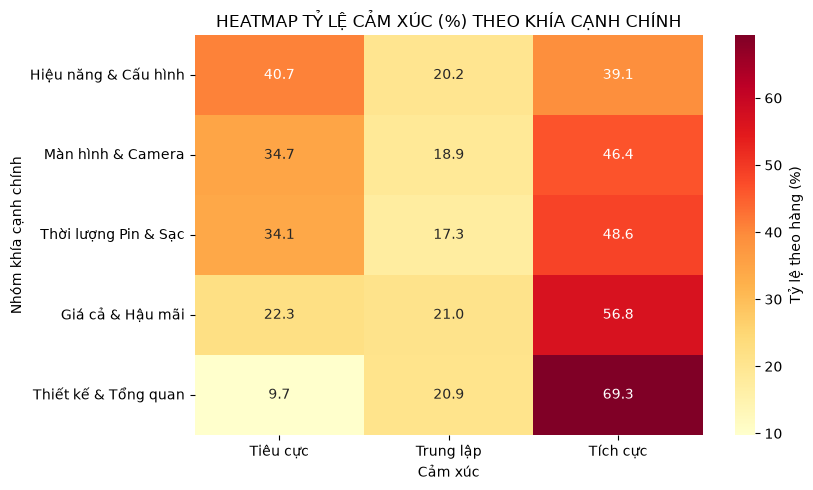

In [19]:
#Vẽ heatmap tỷ lệ phần trăm cảm xúc theo từng nhóm khía cạnh
plt.figure(figsize=(8.5, 5))
sns.heatmap(ct_pct, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Tỷ lệ theo hàng (%)'})
plt.title('HEATMAP TỶ LỆ CẢM XÚC (%) THEO KHÍA CẠNH CHÍNH')
plt.xlabel('Cảm xúc')
plt.ylabel('Nhóm khía cạnh chính')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_aspect_sentiment_heatmap.png'), dpi=300)
plt.show()

In [20]:
#Kiểm tra phân bố cảm xúc (%) trên từng nhãn đa khía cạnh asp_0..asp_4
rows_ml = []
for g in range(5):
    sub = df_train[df_train[f'asp_{g}'] == 1]
    vc = sub['sentiment'].value_counts(normalize=True) * 100
    rows_ml.append({'khia_canh': asp_label_map[g], 'so_cau': len(sub), 'tieu_cuc_%': round(vc.get(0, 0), 1), 'trung_lap_%': round(vc.get(1, 0), 1), 'tich_cuc_%': round(vc.get(2, 0), 1)})
pd.DataFrame(rows_ml)

,khia_canh,so_cau,tieu_cuc_%,trung_lap_%,tich_cuc_%
0,Hiệu năng & Cấu hình,5494,33.9,16.5,49.6
1,Màn hình & Camera,2692,24.4,14.1,61.4
2,Thời lượng Pin & Sạc,3598,25.8,15.2,58.9
3,Giá cả & Hậu mãi,3512,21.8,15.9,62.3
4,Thiết kế & Tổng quan,6151,25.9,20.4,53.7


In [21]:
#Ma trận đồng xuất hiện giữa 5 nhóm đa khía cạnh asp_0..asp_4
co_mat = df_train[asp_cols].T @ df_train[asp_cols]
co_mat.index = [asp_label_map[i] for i in range(5)]
co_mat.columns = [f'asp_{i}' for i in range(5)]
co_mat

,asp_0,asp_1,asp_2,asp_3,asp_4
Hiệu năng & Cấu hình,5494,2058,2597,2351,4212
Màn hình & Camera,2058,2692,1571,1272,2172
Thời lượng Pin & Sạc,2597,1571,3598,1615,2858
Giá cả & Hậu mãi,2351,1272,1615,3512,2935
Thiết kế & Tổng quan,4212,2172,2858,2935,6151


## 5. PHÂN BỐ ĐỘ DÀI TOKEN (WORD COUNT & PHOBERT BPE) CHỌN MAX_LEN

In [22]:
#Nạp PhoBERT tokenizer và đăng ký 5 special tokens PII giống lúc huấn luyện
from transformers import AutoTokenizer
tok_path = os.path.join(ROOT, 'models', 'phobert_multitask')
if not os.path.exists(os.path.join(tok_path, 'vocab.txt')):
    tok_path = 'vinai/phobert-base-v2'
tok = AutoTokenizer.from_pretrained(tok_path)
tok.add_special_tokens({'additional_special_tokens': ['[PHONE]', '[ORDER_ID]', '[EMAIL]', '[URL]', '[PERSON]']})
print('Loaded tokenizer:', tok_path, '| vocab size:', len(tok))

Loaded tokenizer: D:\E-commerce\models\phobert_multitask | vocab size: 64006


In [23]:
#Thử nghiệm đếm số từ và số BPE subword trên mẫu tempt
tempt = df_train['sentence_seg'].iloc[0]
len(tempt.split()), len(tok.encode(tempt, truncation=False))

(30, 39)

In [24]:
#Đo độ dài từ trên sentence_seg và BPE subwords PhoBERT trên toàn bộ tập train
df_train['seg_word_len'] = df_train['sentence_seg'].fillna('').astype(str).apply(lambda t: len(t.split()))
df_train['bpe_len'] = df_train['sentence_seg'].fillna('').astype(str).apply(lambda t: len(tok.encode(t, truncation=False)))

In [25]:
#In mean, p95, p99, max và tỷ lệ <= 256 để chứng minh ngưỡng MAX_LEN = 256
for col, name in [('seg_word_len', 'Word count (sentence_seg)'), ('bpe_len', 'PhoBERT BPE subwords')]:
    s = df_train[col]
    print(f"{name}: mean={s.mean():.2f}, p95={s.quantile(0.95):.0f}, p99={s.quantile(0.99):.0f}, max={s.max()}, <=256={(s <= 256).mean():.2%}")

Word count (sentence_seg): mean=36.62, p95=80, p99=110, max=187, <=256=100.00%
PhoBERT BPE subwords: mean=40.85, p95=86, p99=119, max=200, <=256=100.00%


In [26]:
os.listdir(FIG_DIR)

['eda_aspect_dist.png',
 'eda_aspect_sentiment_heatmap.png',
 'eda_sentiment_dist.png',
 'eda_star_vs_sentiment.png',
 'shap_top_negative_words.png']